In [1]:
%pip install joblib scikit-learn ipykernel

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import sys
import warnings

import joblib
import matplotlib
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import LabelEncoder, StandardScaler

warnings.filterwarnings("ignore")

In [3]:
# ---------------------------------------------------------------------
# CONFIGURATION
# ---------------------------------------------------------------------
RANDOM_STATE = 42
N_CLUSTERS = 4                 # brief: "assume and create 4 clusters"
MIN_REVIEWS_PER_PRODUCT = 5    # ignore products with too few reviews (noisy averages)
OUTPUT_DIR = "artifacts"
SHOW_PLOTS = False             # True -> plt.show() windows, False -> only save PNGs

if not SHOW_PLOTS:
    matplotlib.use("Agg")      # headless backend (works on servers / Streamlit Cloud)
import matplotlib.pyplot as plt  # noqa: E402  (must come after matplotlib.use)

sns.set_theme(style="whitegrid", context="notebook")

RATING_COLS = ["battery_life_rating", "camera_rating", "performance_rating",
               "design_rating", "display_rating"]
MISSING_TOKENS = ["", "na", "n/a", "nan", "null", "none", "-", "--", "?", "unknown"]

# Features used to cluster / compare PRODUCTS (one row per phone model)
PRODUCT_FEATURES = ["avg_price_usd", "avg_rating", "avg_battery", "avg_camera",
                    "avg_performance", "avg_design", "avg_display",
                    "avg_helpful_votes", "positive_ratio", "verified_ratio",
                    "log_reviews"]

# Friendly names used by the preference-based recommender / app sliders
PRIORITY_MAP = {"Battery": "avg_battery", "Camera": "avg_camera",
                "Performance": "avg_performance", "Design": "avg_design",
                "Display": "avg_display"}


def _heading(text):
    print("\n" + "=" * 70 + f"\n{text}\n" + "=" * 70)


PLOTS_ENABLED = True           # run_pipeline(make_plots=False) switches this off


def _save_fig(name, outdir):
    if not PLOTS_ENABLED:
        plt.close()
        return
    os.makedirs(outdir, exist_ok=True)
    plt.tight_layout()
    plt.savefig(os.path.join(outdir, name), dpi=130, bbox_inches="tight")
    if SHOW_PLOTS:
        plt.show()
    plt.close()



In [4]:
df = pd.read_csv('data/Mobile Reviews Sentiment null.csv', encoding="utf-8", encoding_errors="replace",
                     low_memory=False)


In [5]:
df.head()

,review_id,customer_name,age,brand,model,price_usd,price_local,currency,exchange_rate_to_usd,rating,...,language,review_date,verified_purchase,battery_life_rating,camera_rating,performance_rating,design_rating,display_rating,helpful_votes,source
0,1,Aryan Maharaj,45,Realme,Realme 12 Pro,337.31,₹27996.73,INR,83.00,2.0,...,Hindi,11/6/2023,True,1,1,3,2,1,1,Amazon
1,2,Davi Miguel Sousa,18,Realme,Realme 12 Pro,307.78,R$1754.35,BRL,5.70,4.0,...,Portuguese,3/30/2023,True,3,2,4,3,2,5,Flipkart
2,3,Pahal Balay,27,Google,Pixel 6,864.53,₹71755.99,INR,83.00,4.0,...,Hindi,12/7/2022,True,3,5,3,2,4,8,AliExpress
3,4,David Guzman,19,Xiaomi,Redmi Note 13,660.94,د.إ2425.65,AED,3.67,3.0,...,English,3/11/2025,False,1,3,2,1,2,3,Amazon
4,5,Yago Leão,38,Motorola,Edge 50,792.13,R$4515.14,BRL,5.70,3.0,...,Portuguese,9/29/2023,True,3,3,2,2,1,0,BestBuy


In [6]:
print(f"Loaded '{'data/Mobile Reviews Sentiment null.csv'}'  ->  {df.shape[0]:,} rows x {df.shape[1]} columns")

Loaded 'data/Mobile Reviews Sentiment null.csv'  ->  50,000 rows x 22 columns


In [7]:
def inspect_data(df):
    _heading("STEP 2: RAW DATA INSPECTION")
    print("First 5 rows:\n", df.head(), "\n")
    print("Data types:\n", df.dtypes, "\n")
    miss = df.isnull().sum()
    print("Missing values per column:\n", miss[miss > 0] if miss.any() else "none", "\n")
    print("Fully duplicated rows:", df.duplicated().sum())
    print("\nNumeric summary:\n", df.describe().T)
inspect_data(df)


STEP 2: RAW DATA INSPECTION
First 5 rows:
    review_id      customer_name  age     brand          model  price_usd  \
0          1      Aryan Maharaj   45    Realme  Realme 12 Pro     337.31   
1          2  Davi Miguel Sousa   18    Realme  Realme 12 Pro     307.78   
2          3        Pahal Balay   27    Google        Pixel 6     864.53   
3          4       David Guzman   19    Xiaomi  Redmi Note 13     660.94   
4          5          Yago Leão   38  Motorola        Edge 50     792.13   

  price_local currency  exchange_rate_to_usd  rating  ...    language  \
0   ₹27996.73      INR                 83.00     2.0  ...       Hindi   
1   R$1754.35      BRL                  5.70     4.0  ...  Portuguese   
2   ₹71755.99      INR                 83.00     4.0  ...       Hindi   
3  د.إ2425.65      AED                  3.67     3.0  ...     English   
4   R$4515.14      BRL                  5.70     3.0  ...  Portuguese   

  review_date verified_purchase battery_life_rating  camera_

In [8]:
df.describe()

,review_id,age,price_usd,exchange_rate_to_usd,rating,battery_life_rating,camera_rating,performance_rating,design_rating,display_rating,helpful_votes
count,50000.000000,50000.000000,47550.00000,50000.000000,47547.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,25000.500000,30.075220,689.89277,12.057946,3.123415,2.71800,2.717640,2.719620,2.713960,2.721280,3.644180
std,14433.901067,8.931307,310.32722,26.553332,1.249067,1.34827,1.345001,1.349208,1.343346,1.352121,2.432745
min,1.000000,18.000000,180.02000,0.780000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,12500.750000,23.000000,450.75500,1.000000,2.000000,1.00000,1.000000,1.000000,1.000000,1.000000,2.000000
50%,25000.500000,29.000000,637.58500,1.530000,3.000000,3.00000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,37500.250000,36.000000,901.45750,5.700000,4.000000,4.00000,4.000000,4.000000,4.000000,4.000000,5.000000
max,50000.000000,65.000000,1499.89000,83.000000,5.000000,5.00000,5.000000,5.000000,5.000000,5.000000,17.000000


In [9]:
# =====================================================================
# STEP 3 - DATA CLEANING  (missing values & duplicates, step by step)
# =====================================================================
def to_number(series):
    """Convert messy text like '$1,010.68 ' or '₹27996.73' to a float.

    1. astype(str)                -> work on text
    2. regex [^0-9.\\-] removed   -> strip currency symbols, commas, spaces
    3. to_numeric(errors=coerce)  -> anything still invalid becomes NaN
    """
    cleaned = series.astype(str).str.replace(r"[^0-9.\-]", "", regex=True)
    return pd.to_numeric(cleaned, errors="coerce")



def canonical_case(series):
    """Make spelling consistent, e.g. 'apple', 'APPLE', 'Apple' -> 'Apple'.
    For each lower-case spelling we keep the most frequent original spelling.
    (Safer than .title(), which would turn 'iPhone' into 'Iphone'.)"""
    s = series.astype("object")
    key = s.str.lower()
    best = s.groupby(key).agg(lambda x: x.value_counts().idxmax())
    return key.map(best).where(s.notna())

print(df.columns)

Index(['review_id', 'customer_name', 'age', 'brand', 'model', 'price_usd',
       'price_local', 'currency', 'exchange_rate_to_usd', 'rating',
       'sentiment', 'country', 'language', 'review_date', 'verified_purchase',
       'battery_life_rating', 'camera_rating', 'performance_rating',
       'design_rating', 'display_rating', 'helpful_votes', 'source'],
      dtype='str')


In [10]:
df["brand"] = canonical_case(df["brand"])
df["price_usd"] = to_number(df["price_usd"])
df["price_local"] = to_number(df["price_local"])

df[["brand","price_usd","price_local"]].head()


,brand,price_usd,price_local
0,Realme,337.31,27996.73
1,Realme,307.78,1754.35
2,Google,864.53,71755.99
3,Xiaomi,660.94,NaN
4,Motorola,792.13,4515.14


In [11]:
def clean_data(df_raw):
    
    """Return (clean_df, report_dict).  Every sub-step is explained below."""
    _heading("STEP 3: DATA CLEANING")
    df = df_raw.copy()
    report = {"rows_raw": len(df)}

    # 3.1 Standardise column names ------------------------------------
    # Lower-case, no spaces -> avoids KeyErrors caused by ' Rating' vs 'rating'.
    df.columns = (df.columns.str.strip().str.lower()
                  .str.replace(r"\s+", "_", regex=True))
    print("3.1 Column names standardised.")

    # 3.2 Trim text & convert 'fake' missing values to real NaN -------
    # Values such as "", "N/A", "null", "-" are not recognised by pandas as
    # missing. Converting them to NaN means one consistent missing-value
    # strategy works for every column.
    # astype("string") also handles mixed columns such as True/False/NaN.
    text_cols = df.select_dtypes(include=["object", "string"]).columns
    for c in text_cols:
        s = df[c].astype("string").str.strip()
        s = s.mask(s.str.lower().isin(MISSING_TOKENS))
        df[c] = s.astype("object").where(s.notna(), np.nan)
    print("3.2 Whitespace trimmed, placeholder strings ('N/A','null','-') -> NaN.")

    # 3.3 Fix data types ----------------------------------------------
    # Numbers stored as text can't be averaged or scaled, so convert them.
    for c in ["age", "price_usd", "rating", "helpful_votes"] + RATING_COLS:
        df[c] = to_number(df[c])
    # review_date: expected m/d/Y; fall back to pandas' generic parser.
    d = pd.to_datetime(df["review_date"], format="%m/%d/%Y", errors="coerce")
    df["review_date"] = d.fillna(pd.to_datetime(df["review_date"], errors="coerce"))
    # verified_purchase: True/False text -> 1/0
    df["verified_purchase"] = (df["verified_purchase"].astype(str).str.strip().str.lower()
                               .map({"true": 1, "yes": 1, "1": 1, "1.0": 1,
                                     "false": 0, "no": 0, "0": 0, "0.0": 0}))
    print("3.3 Data types fixed (numbers, dates, verified_purchase -> 0/1).")

df.head

<bound method NDFrame.head of        review_id          customer_name  age     brand            model  \
0              1          Aryan Maharaj   45    Realme    Realme 12 Pro   
1              2      Davi Miguel Sousa   18    Realme    Realme 12 Pro   
2              3            Pahal Balay   27    Google          Pixel 6   
3              4           David Guzman   19    Xiaomi    Redmi Note 13   
4              5              Yago Leão   38  Motorola          Edge 50   
...          ...                    ...  ...       ...              ...   
49995      49996          Rebecca Pratt   18    Realme    Realme 12 Pro   
49996      49997  Dr. Tiffany Patterson   28   Samsung   Galaxy Note 20   
49997      49998        Alexandra Singh   21     Apple        iPhone SE   
49998      49999          Robert Morris   31    Realme  Realme Narzo 70   
49999      50000       Regina Dennis MD   44  Motorola     Moto G Power   

       price_usd  price_local currency  exchange_rate_to_usd  rating 

In [12]:
df

,review_id,customer_name,age,brand,model,price_usd,price_local,currency,exchange_rate_to_usd,rating,...,language,review_date,verified_purchase,battery_life_rating,camera_rating,performance_rating,design_rating,display_rating,helpful_votes,source
0,1,Aryan Maharaj,45,Realme,Realme 12 Pro,337.31,27996.73,INR,83.00,2.0,...,Hindi,11/6/2023,True,1,1,3,2,1,1,Amazon
1,2,Davi Miguel Sousa,18,Realme,Realme 12 Pro,307.78,1754.35,BRL,5.70,4.0,...,Portuguese,3/30/2023,True,3,2,4,3,2,5,Flipkart
2,3,Pahal Balay,27,Google,Pixel 6,864.53,71755.99,INR,83.00,4.0,...,Hindi,12/7/2022,True,3,5,3,2,4,8,AliExpress
3,4,David Guzman,19,Xiaomi,Redmi Note 13,660.94,NaN,AED,3.67,3.0,...,English,3/11/2025,False,1,3,2,1,2,3,Amazon
4,5,Yago Leão,38,Motorola,Edge 50,792.13,4515.14,BRL,5.70,3.0,...,Portuguese,9/29/2023,True,3,3,2,2,1,0,BestBuy
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49996,Rebecca Pratt,18,Realme,Realme 12 Pro,526.10,804.93,AUD,1.53,4.0,...,English,8/17/2023,False,3,3,4,3,5,4,BestBuy
49996,49997,Dr. Tiffany Patterson,28,Samsung,Galaxy Note 20,911.85,1395.13,AUD,1.53,3.0,...,English,9/23/2023,False,3,2,4,1,3,2,AliExpress
49997,49998,Alexandra Singh,21,Apple,iPhone SE,1155.32,NaN,AED,3.67,NaN,...,English,4/4/2023,True,2,3,4,4,5,4,Amazon
49998,49999,Robert Morris,31,Realme,Realme Narzo 70,459.04,NaN,USD,1.00,3.0,...,English,7/11/2025,True,1,2,2,1,3,6,NaN


In [13]:
# 3.4 Remove duplicates -------------------------------------------
    # (a) same review re-ingested with a NEW id -> compare all columns except id
report={}
cols_wo_id = [c for c in df.columns if c != "review_id"]

n0 = len(df)

df = df.drop_duplicates(subset=cols_wo_id, keep="first")
report["duplicates_same_content"] = n0 - len(df)
    # (b) the same review_id appearing twice
n1 = len(df)
df = df[~(df.duplicated(subset="review_id", keep="first") & df["review_id"].notna())]
report["duplicates_same_id"] = n1 - len(df)

print(f"3.4 Duplicates removed: {report['duplicates_same_content']} identical-content "
      f"+ {report['duplicates_same_id']} repeated review_id.")

3.4 Duplicates removed: 0 identical-content + 0 repeated review_id.


In [14]:
df.duplicated().sum

<bound method Series.sum of 0        False
1        False
2        False
3        False
4        False
         ...  
49995    False
49996    False
49997    False
49998    False
49999    False
Length: 50000, dtype: bool>

In [15]:
# 3.5 Drop columns we will not use ---------------------------------
    # price_local is text in 10 different currency formats; price_usd is
    # already normalised, so it is the only price we need.
df = df.drop(columns=["price_local"], errors="ignore")
print("3.5 Dropped 'price_local' (messy currency text; price_usd is used instead).")

df.columns

3.5 Dropped 'price_local' (messy currency text; price_usd is used instead).


Index(['review_id', 'customer_name', 'age', 'brand', 'model', 'price_usd',
       'currency', 'exchange_rate_to_usd', 'rating', 'sentiment', 'country',
       'language', 'review_date', 'verified_purchase', 'battery_life_rating',
       'camera_rating', 'performance_rating', 'design_rating',
       'display_rating', 'helpful_votes', 'source'],
      dtype='str')

In [16]:
# 3.6 Invalid values -> NaN (then treated as missing) --------------
df.loc[~df["age"].between(10, 100), "age"] = np.nan
for c in ["rating"] + RATING_COLS:
    df.loc[~df[c].between(1, 5), c] = np.nan
    df.loc[df["price_usd"] <= 0, "price_usd"] = np.nan
    df.loc[df["helpful_votes"] < 0, "helpful_votes"] = np.nan
    print("3.6 Impossible values (age outside 10-100, ratings outside 1-5, "
          "price <= 0, votes < 0) set to NaN.")

df[["age","rating","price_usd","helpful_votes"]]

3.6 Impossible values (age outside 10-100, ratings outside 1-5, price <= 0, votes < 0) set to NaN.
3.6 Impossible values (age outside 10-100, ratings outside 1-5, price <= 0, votes < 0) set to NaN.
3.6 Impossible values (age outside 10-100, ratings outside 1-5, price <= 0, votes < 0) set to NaN.
3.6 Impossible values (age outside 10-100, ratings outside 1-5, price <= 0, votes < 0) set to NaN.
3.6 Impossible values (age outside 10-100, ratings outside 1-5, price <= 0, votes < 0) set to NaN.
3.6 Impossible values (age outside 10-100, ratings outside 1-5, price <= 0, votes < 0) set to NaN.


,age,rating,price_usd,helpful_votes
0,45.0,2.0,337.31,1.0
1,18.0,4.0,307.78,5.0
2,27.0,4.0,864.53,8.0
3,19.0,3.0,660.94,3.0
4,38.0,3.0,792.13,0.0
...,...,...,...,...
49995,18.0,4.0,526.10,4.0
49996,28.0,3.0,911.85,2.0
49997,21.0,NaN,1155.32,4.0
49998,31.0,3.0,459.04,6.0


In [17]:
df.isnull().sum()

review_id                  0
customer_name              0
age                        0
brand                      0
model                      0
price_usd               2450
currency                   0
exchange_rate_to_usd       0
rating                  2453
sentiment               2445
country                    0
language                   0
review_date                0
verified_purchase          0
battery_life_rating        0
camera_rating              0
performance_rating         0
design_rating              0
display_rating             0
helpful_votes              0
source                  2448
dtype: int64

In [18]:
   # 3.7 Missing values ----------------------------------------------
miss = df.isnull().sum()
report["missing_before"] = miss[miss > 0].to_dict()
print("\n3.7 Missing values BEFORE filling:\n", miss[miss > 0] if miss.any() else "none")

    # (a) Rows without brand/model cannot be attributed to a product -> drop.
n2 = len(df)
df = df.dropna(subset=["brand", "model"]).copy()
report["dropped_no_product"] = n2 - len(df)

    # canonical spelling for categorical columns (after brand/model exist)
for c in ["brand", "model", "country", "language", "source"]:
    df[c] = canonical_case(df[c])
    df["sentiment"] = df["sentiment"].str.title()

    


3.7 Missing values BEFORE filling:
 price_usd    2450
rating       2453
sentiment    2445
source       2448
dtype: int64


In [19]:
# (b) Numeric columns: fill with the MEDIAN of the same phone model
    #     (a Pixel 6 review is best estimated from other Pixel 6 reviews);
    #     if the whole model is empty, use the global median.
    #     Median (not mean) because it is robust to outliers.
for c in ["price_usd", "rating"] + RATING_COLS:
    df[c] = df[c].fillna(df.groupby("model")[c].transform("median"))
    df[c] = df[c].fillna(df[c].median())
    df["age"] = df["age"].fillna(df["age"].median()).round().astype(int)
    df["helpful_votes"] = df["helpful_votes"].fillna(0)   # no votes recorded = 0

    # (c) verified_purchase: binary flag -> fill with the most common value
    df["verified_purchase"] = df["verified_purchase"].fillna(df["verified_purchase"].mode()[0]).astype(int)

   

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   review_id             50000 non-null  int64  
 1   customer_name         50000 non-null  str    
 2   age                   50000 non-null  int64  
 3   brand                 50000 non-null  str    
 4   model                 50000 non-null  str    
 5   price_usd             50000 non-null  float64
 6   currency              50000 non-null  str    
 7   exchange_rate_to_usd  50000 non-null  float64
 8   rating                50000 non-null  float64
 9   sentiment             47555 non-null  str    
 10  country               50000 non-null  str    
 11  language              50000 non-null  str    
 12  review_date           50000 non-null  str    
 13  verified_purchase     50000 non-null  int64  
 14  battery_life_rating   50000 non-null  float64
 15  camera_rating         50000 no

In [21]:
 # (d) sentiment: infer from rating using the most common sentiment seen
    #     for that rating in the rows that DO have both.
known = df.dropna(subset=["sentiment"])
by_rating = known.groupby(known["rating"].round())["sentiment"].agg(lambda s: s.mode().iloc[0])
df["sentiment"] = df["sentiment"].fillna(df["rating"].round().map(by_rating)).fillna("Neutral")

    # (e) other categoricals (country, language, source): label as 'Unknown'
    #     rather than guessing - keeps the row, flags the gap.
for c in ["country", "language", "source", "currency"]:
    if c in df:
        df[c] = df[c].fillna("Unknown")

    # (f) dates: fill with the median date so time features still work
if "review_date" in df:
    #converted text columns to actual date
    df["review_date"]=pd.to_datetime(df["review_date"],errors="coerce")
    median_date=df["review_date"].median()

df["review_date"] = df["review_date"].fillna(median_date)
print("3.7 Missing values filled (model-median / mode / inferred / 'Unknown').")

3.7 Missing values filled (model-median / mode / inferred / 'Unknown').


In [22]:
df.isnull().sum()

review_id               0
customer_name           0
age                     0
brand                   0
model                   0
price_usd               0
currency                0
exchange_rate_to_usd    0
rating                  0
sentiment               0
country                 0
language                0
review_date             0
verified_purchase       0
battery_life_rating     0
camera_rating           0
performance_rating      0
design_rating           0
display_rating          0
helpful_votes           0
source                  0
dtype: int64

In [23]:
# 3.8 Outliers: winsorise (cap) extreme values --------------------
    # Clip to the 1st-99th percentile so a few extreme prices/votes do not
    # distort K-Means (distance-based, very sensitive to outliers).
for c in ["price_usd", "helpful_votes"]:
    lo, hi = df[c].quantile([0.01, 0.99])
    df[c] = df[c].clip(lo, hi)
    print("3.8 price_usd & helpful_votes capped at the 1st/99th percentile.")
    

3.8 price_usd & helpful_votes capped at the 1st/99th percentile.
3.8 price_usd & helpful_votes capped at the 1st/99th percentile.


In [24]:
df[["price_usd","helpful_votes"]].describe()

,price_usd,helpful_votes
count,50000.000000,50000.000000
mean,689.613195,3.630940
std,306.416032,2.391646
min,205.329400,0.000000
25%,450.800000,2.000000
50%,640.805000,3.000000
75%,901.405000,5.000000
max,1442.401600,10.000000


In [25]:
# 3.9 Friendly product name: 'Apple iPhone 14', 'Realme 12 Pro' ----
report={}
report['rows_raw'] = len(df)
starts = [
    str(m).lower().startswith(str(b).lower())
    for m,b in zip(df["model"], df["brand"])
]
df["product"] = np.where(starts, df["model"], df["brand"] + " " + df["model"])

df = df.reset_index(drop=True)
report["rows_clean"] = len(df)
report["missing_after"] = int(df.isnull().sum().sum())

print(f"Cleaning finished: {report['rows_raw']:,} -> {report['rows_clean']:,} rows | "
      f"missing values left: {report['missing_after']}")



Cleaning finished: 50,000 -> 50,000 rows | missing values left: 0


In [26]:
print("---Sample of the new 'product' column ---")
print(df[['brand','model','product']].sample(10))

---Sample of the new 'product' column ---
          brand            model               product
10674     Apple        iPhone 14       Apple iPhone 14
30277    Xiaomi    Redmi Note 13  Xiaomi Redmi Note 13
25037    Google          Pixel 8        Google Pixel 8
23051    Realme  Realme Narzo 70       Realme Narzo 70
16038    Realme  Realme Narzo 70       Realme Narzo 70
44726  Motorola          Razr 40      Motorola Razr 40
4695    Samsung       Galaxy S24    Samsung Galaxy S24
16135   OnePlus      OnePlus 11R           OnePlus 11R
18559   Samsung       Galaxy A55    Samsung Galaxy A55
5038      Apple        iPhone 13       Apple iPhone 13


In [27]:
# =====================================================================
# STEP 4 - FEATURE ENGINEERING
# =====================================================================
def engineer_features(df):
    _heading("STEP 4: FEATURE ENGINEERING")
    df = df.copy()
    df["avg_feature_rating"] = df[RATING_COLS].mean(axis=1)           # overall spec quality
    df["review_year"] = df["review_date"].dt.year
    df["review_month"] = df["review_date"].dt.month
    df["age_group"] = pd.cut(df["age"], [0, 24, 34, 44, 54, 120],
                             labels=["<25", "25-34", "35-44", "45-54", "55+"]).astype(str)
    df["sentiment_score"] = df["sentiment"].map({"Negative": -1, "Neutral": 0, "Positive": 1}).fillna(0)
    df["value_for_money"] = df["avg_feature_rating"] / (df["price_usd"] / 100)   # rating points per $100
    df["engagement_score"] = df["helpful_votes"] * (1 + 0.5 * df["verified_purchase"])
    df["price_tier"] = pd.qcut(df["price_usd"], 3, labels=["Budget", "Mid-range", "Premium"]).astype(str)
    print("Added: avg_feature_rating, review_year/month, age_group, sentiment_score, "
          "value_for_money, engagement_score, price_tier")
    return df

df.head(10)
df.describe()


,review_id,age,price_usd,exchange_rate_to_usd,rating,review_date,verified_purchase,battery_life_rating,camera_rating,performance_rating,design_rating,display_rating,helpful_votes
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000,50000.00000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,25000.500000,30.075220,689.613195,12.057946,3.117360,2024-04-20 09:24:46.080000,0.80140,2.71800,2.717640,2.719620,2.713960,2.721280,3.630940
min,1.000000,18.000000,205.329400,0.780000,1.000000,2022-10-22 00:00:00,0.00000,1.00000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,12500.750000,23.000000,450.800000,1.000000,2.000000,2023-07-20 00:00:00,1.00000,1.00000,1.000000,1.000000,1.000000,1.000000,2.000000
50%,25000.500000,29.000000,640.805000,1.530000,3.000000,2024-04-21 00:00:00,1.00000,3.00000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,37500.250000,36.000000,901.405000,5.700000,4.000000,2025-01-20 00:00:00,1.00000,4.00000,4.000000,4.000000,4.000000,4.000000,5.000000
max,50000.000000,65.000000,1442.401600,83.000000,5.000000,2025-10-21 00:00:00,1.00000,5.00000,5.000000,5.000000,5.000000,5.000000,10.000000
std,14433.901067,8.931307,306.416032,26.553332,1.218333,NaN,0.39895,1.34827,1.345001,1.349208,1.343346,1.352121,2.391646


In [28]:
def build_product_table(df, min_reviews=MIN_REVIEWS_PER_PRODUCT):
    """Aggregate review-level rows -> ONE row per phone model (for clustering
    and recommendation)."""
    g = df.groupby(["product", "brand"]).agg(
        avg_price_usd=("price_usd", "mean"),
        avg_rating=("rating", "mean"),
        avg_battery=("battery_life_rating", "mean"),
        avg_camera=("camera_rating", "mean"),
        avg_performance=("performance_rating", "mean"),
        avg_design=("design_rating", "mean"),
        avg_display=("display_rating", "mean"),
        avg_helpful_votes=("helpful_votes", "mean"),
        positive_ratio=("sentiment", lambda s: (s == "Positive").mean()),
        verified_ratio=("verified_purchase", "mean"),
        avg_value_for_money=("value_for_money", "mean"),
        n_reviews=("rating", "size"),
    ).reset_index()
    g["log_reviews"] = np.log1p(g["n_reviews"])      # popularity, tamed with log
    g = g[g["n_reviews"] >= min_reviews].reset_index(drop=True)
    print(f"Product table: {len(g)} products (>= {min_reviews} reviews each)")
    return g
df.head(10)


,review_id,customer_name,age,brand,model,price_usd,currency,exchange_rate_to_usd,rating,sentiment,...,review_date,verified_purchase,battery_life_rating,camera_rating,performance_rating,design_rating,display_rating,helpful_votes,source,product
0,1,Aryan Maharaj,45,Realme,Realme 12 Pro,337.3100,INR,83.00,2.0,Negative,...,2023-11-06,1,1.0,1.0,3.0,2.0,1.0,1.0,Amazon,Realme 12 Pro
1,2,Davi Miguel Sousa,18,Realme,Realme 12 Pro,307.7800,BRL,5.70,4.0,Positive,...,2023-03-30,1,3.0,2.0,4.0,3.0,2.0,5.0,Flipkart,Realme 12 Pro
2,3,Pahal Balay,27,Google,Pixel 6,864.5300,INR,83.00,4.0,Positive,...,2022-12-07,1,3.0,5.0,3.0,2.0,4.0,8.0,AliExpress,Google Pixel 6
3,4,David Guzman,19,Xiaomi,Redmi Note 13,660.9400,AED,3.67,3.0,Positive,...,2025-03-11,0,1.0,3.0,2.0,1.0,2.0,3.0,Amazon,Xiaomi Redmi Note 13
4,5,Yago Leão,38,Motorola,Edge 50,792.1300,BRL,5.70,3.0,Neutral,...,2023-09-29,1,3.0,3.0,2.0,2.0,1.0,0.0,BestBuy,Motorola Edge 50
5,6,Lara Abreu,38,Apple,iPhone 14,948.7900,BRL,5.70,5.0,Positive,...,2023-06-27,0,5.0,4.0,5.0,5.0,4.0,6.0,AliExpress,Apple iPhone 14
6,7,Gina Moore,40,OnePlus,OnePlus 12,420.1300,AED,3.67,3.0,Positive,...,2024-03-27,0,3.0,3.0,2.0,1.0,2.0,2.0,eBay,OnePlus 12
7,8,James Howard,39,Apple,iPhone SE,1442.4016,AUD,1.53,2.0,Negative,...,2024-04-08,1,2.0,1.0,2.0,2.0,2.0,3.0,Amazon,Apple iPhone SE
8,9,Rosalia Beyer,32,Realme,Realme 12 Pro,275.7300,EUR,0.93,4.0,Positive,...,2024-10-04,0,4.0,3.0,2.0,3.0,3.0,8.0,eBay,Realme 12 Pro
9,10,Valerie Gray,31,OnePlus,OnePlus Nord 3,545.5700,AUD,1.53,3.0,Positive,...,2025-02-25,1,2.0,2.0,3.0,3.0,2.0,4.0,BestBuy,OnePlus Nord 3


In [29]:
# =====================================================================
# STEP 5 - EXPLORATORY DATA ANALYSIS
# =====================================================================

def run_eda(df, products, outdir=OUTPUT_DIR):
    _heading("STEP 5: EXPLORATORY DATA ANALYSIS")

    # --- statistical summaries ---
    print("Reviews per brand:\n", df["brand"].value_counts().to_string(), "\n")
    print("Reviews per country:\n", df["country"].value_counts().to_string(), "\n")
    print("Top 5 rated products:\n",
          products.nlargest(5, "avg_rating")[["product", "avg_rating", "n_reviews"]].to_string(index=False))
    print("\nLowest 5 rated products:\n",
          products.nsmallest(5, "avg_rating")[["product", "avg_rating", "n_reviews"]].to_string(index=False))
    r, p = pearsonr(products["avg_price_usd"], products["avg_rating"])
    print(f"\nPrice vs rating (product level): Pearson r = {r:.3f}, p-value = {p:.4f}")
    print("\nAverage rating by brand:\n", df.groupby("brand")["rating"].mean().sort_values(ascending=False).round(2).to_string())

    


In [30]:
%matplotlib inline
import matplotlib.pyplot as plt


import seaborn as sns
import plotly.express as px

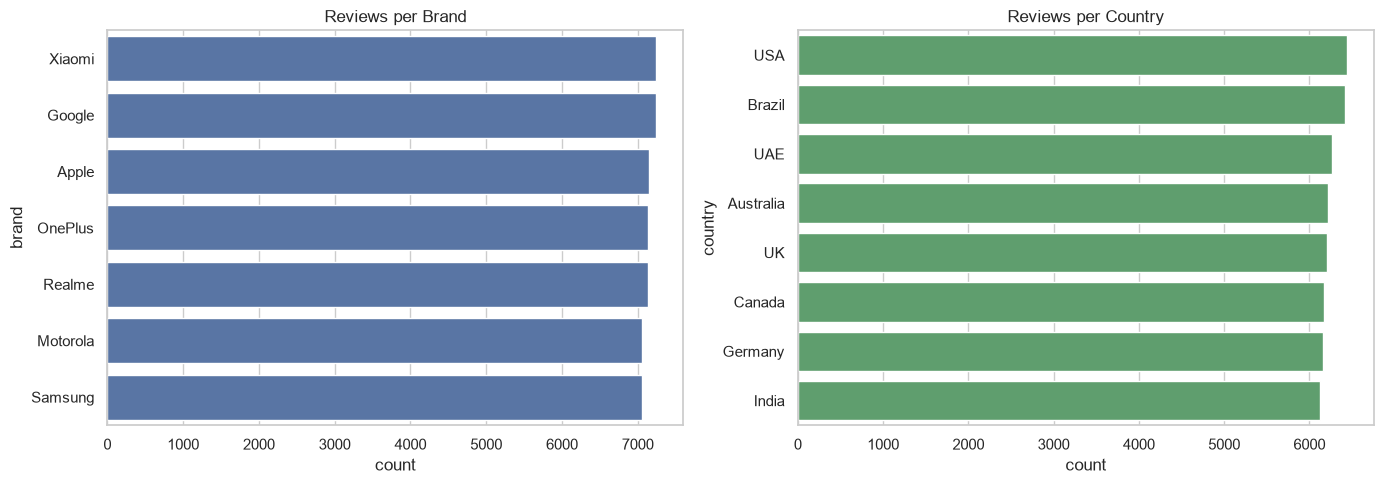

In [31]:
# --- plots ---
outdir="."
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, y="brand", order=df["brand"].value_counts().index, ax=ax[0], color="#4C72B0")
ax[0].set_title("Reviews per Brand")
sns.countplot(data=df, y="country", order=df["country"].value_counts().index, ax=ax[1], color="#55A868")
ax[1].set_title("Reviews per Country")

plt.tight_layout()
plt.show()
   

Text(0, 0.5, 'share of reviews')

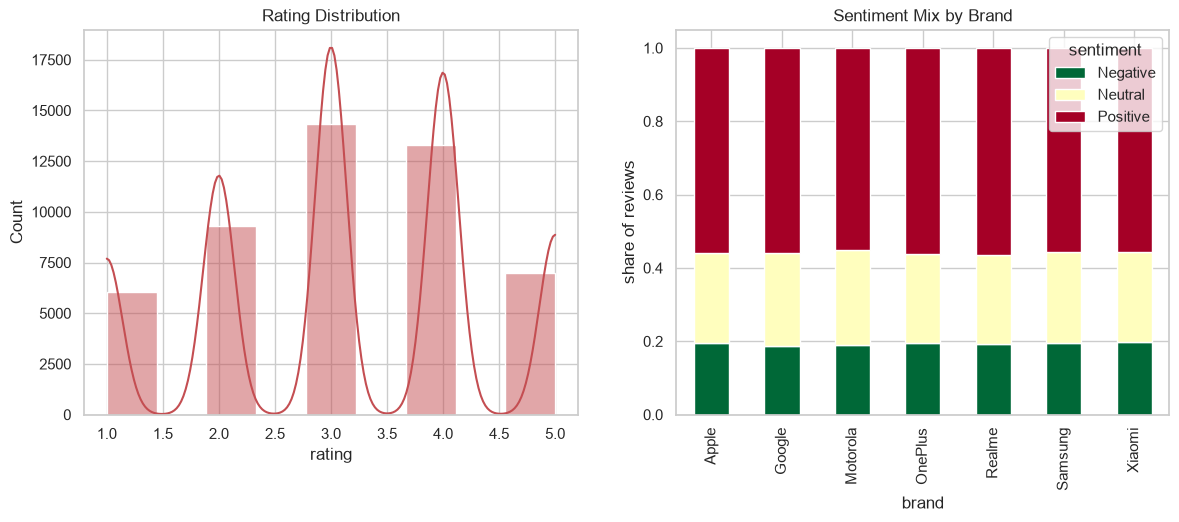

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df["rating"], bins=9, kde=True, ax=ax[0], color="#C44E52")
ax[0].set_title("Rating Distribution")
sent = pd.crosstab(df["brand"], df["sentiment"], normalize="index")
sent.plot(kind="bar", stacked=True, ax=ax[1], colormap="RdYlGn_r")
ax[1].set_title("Sentiment Mix by Brand")
ax[1].set_ylabel("share of reviews")

    

    

In [33]:
df.columns

Index(['review_id', 'customer_name', 'age', 'brand', 'model', 'price_usd',
       'currency', 'exchange_rate_to_usd', 'rating', 'sentiment', 'country',
       'language', 'review_date', 'verified_purchase', 'battery_life_rating',
       'camera_rating', 'performance_rating', 'design_rating',
       'display_rating', 'helpful_votes', 'source', 'product'],
      dtype='str')

Text(0.5, 1.0, 'Lowest 10 Rated Products')

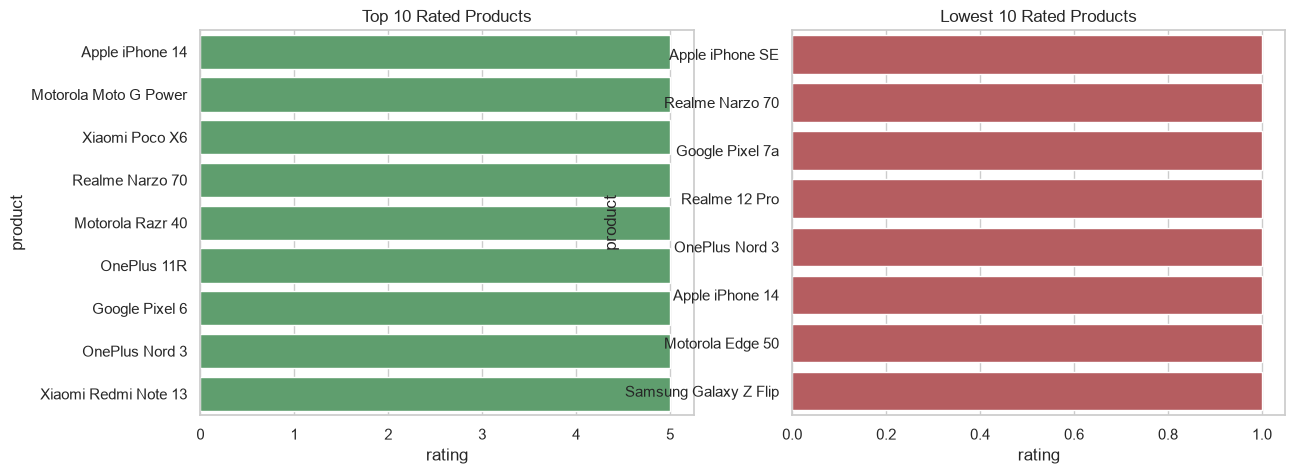

In [34]:
top = df.nlargest(10, "rating")
bottom = df.nsmallest(10, "rating")
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=top, y="product", x="rating", ax=ax[0], color="#55A868")
ax[0].set_title("Top 10 Rated Products")
sns.barplot(data=bottom, y="product", x="rating", ax=ax[1], color="#C44E52")
ax[1].set_title("Lowest 10 Rated Products")                  

Text(0.5, 1.0, 'Price Distribution by Brand')

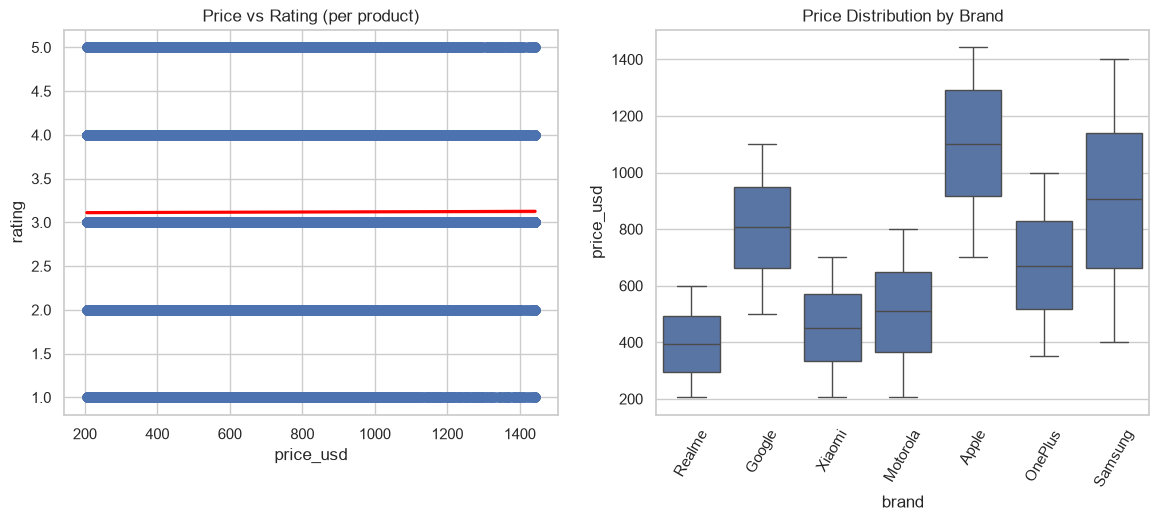

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.regplot(data=df, x="price_usd", y="rating", ax=ax[0],
scatter_kws={"alpha": .7}, line_kws={"color": "red"})
ax[0].set_title("Price vs Rating (per product)")
sns.boxplot(data=df, x="brand", y="price_usd", ax=ax[1])
ax[1].tick_params(axis="x", rotation=60)
ax[1].set_title("Price Distribution by Brand")

In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   review_id             50000 non-null  int64         
 1   customer_name         50000 non-null  str           
 2   age                   50000 non-null  int64         
 3   brand                 50000 non-null  str           
 4   model                 50000 non-null  str           
 5   price_usd             50000 non-null  float64       
 6   currency              50000 non-null  str           
 7   exchange_rate_to_usd  50000 non-null  float64       
 8   rating                50000 non-null  float64       
 9   sentiment             50000 non-null  str           
 10  country               50000 non-null  str           
 11  language              50000 non-null  str           
 12  review_date           50000 non-null  datetime64[us]
 13  verified_purchase     50000

Text(0.5, 1.0, 'Correlation Heatmap')

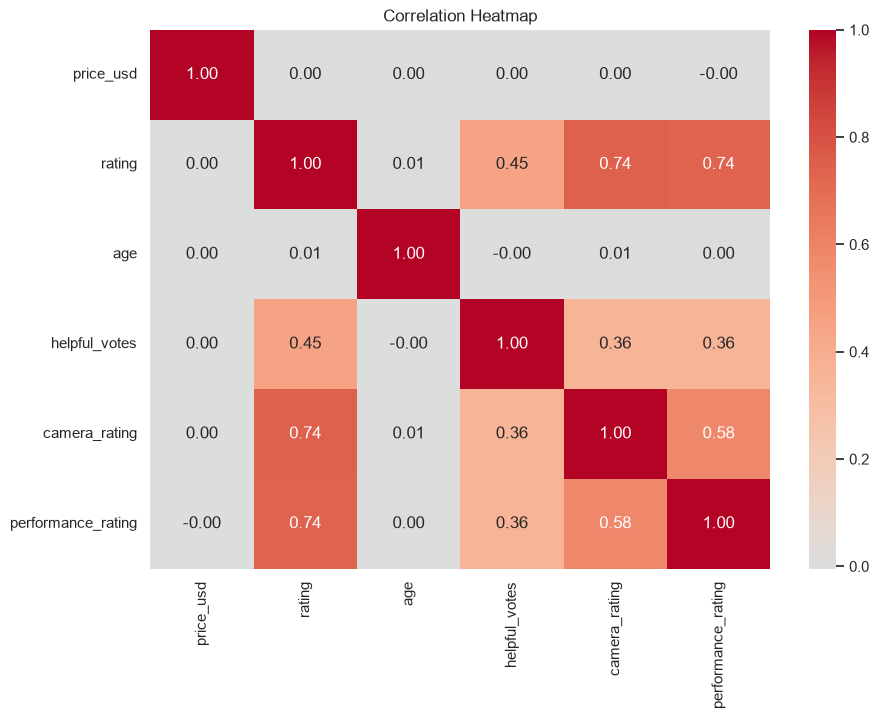

In [37]:
num = ["price_usd", "rating", "age", "helpful_votes","camera_rating","performance_rating"] 
plt.figure(figsize=(10, 7))
sns.heatmap(df[num].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")                                       

Text(0.5, 1.0, 'Reviews per Month')

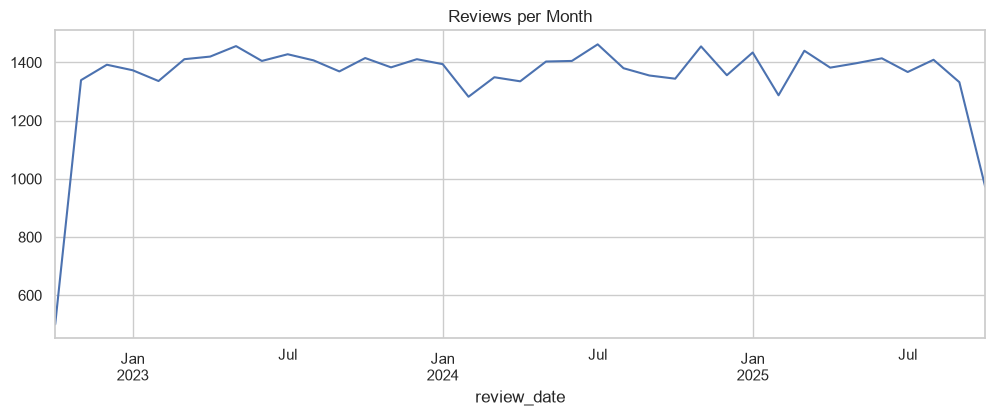

In [38]:
monthly = df.set_index("review_date").resample("ME")["rating"].agg(["size", "mean"])
fig, ax = plt.subplots(figsize=(12, 4))
monthly["size"].plot(ax=ax, color="#4C72B0")
ax.set_title("Reviews per Month")
                                                        

In [39]:
df.columns

Index(['review_id', 'customer_name', 'age', 'brand', 'model', 'price_usd',
       'currency', 'exchange_rate_to_usd', 'rating', 'sentiment', 'country',
       'language', 'review_date', 'verified_purchase', 'battery_life_rating',
       'camera_rating', 'performance_rating', 'design_rating',
       'display_rating', 'helpful_votes', 'source', 'product'],
      dtype='str')

In [40]:
# =====================================================================
# STEP 6 - ENCODING & SCALING
# =====================================================================
def encode_categoricals(df):
    """Label-encode identifiers (brand/model/country/language/source) and
    one-hot-encode sentiment.
      * LabelEncoder  -> compact integer codes (fine for IDs / tree models,
                         NOT used directly as K-Means input because the
                         numbers imply a false order)
      * One-hot       -> 0/1 columns, safe for distance-based algorithms"""
    enc = df.copy()
    encoders = {}
    for col in ["brand", "model", "country", "language", "source"]:
        le = LabelEncoder()
        enc[col + "_enc"] = le.fit_transform(enc[col].astype(str))
        encoders[col] = le
    enc = pd.concat([enc, pd.get_dummies(enc["sentiment"], prefix="sent", dtype=int)], axis=1)
    return enc, encoders


def scale_features(frame, features):
    """StandardScaler: (x - mean) / std  -> every feature has mean 0, std 1.
    K-Means uses Euclidean distance, so unscaled 'price' (hundreds) would
    swamp 'rating' (1-5)."""
    scaler = StandardScaler()
    X = scaler.fit_transform(frame[features])
    return X, scaler

df_encoded, encoders=encode_categoricals(df)

df_encoded.head()

features_to_scale =["price_usd","rating"]
X_scaled, feature_scaler = scale_features(df_encoded, features_to_scale)
print("Scaled data shape:",X_scaled.shape)
print("\nFirst 5 rows of scaled data:\n",X_scaled[:5])





Scaled data shape: (50000, 2)

First 5 rows of scaled data:
 [[-1.14976594 -0.91713086]
 [-1.24613915  0.72447231]
 [ 0.57085314  0.72447231]
 [-0.09357696 -0.09632927]
 [ 0.33457071 -0.09632927]]


In [41]:
df.info()
df.shape
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   review_id             50000 non-null  int64         
 1   customer_name         50000 non-null  str           
 2   age                   50000 non-null  int64         
 3   brand                 50000 non-null  str           
 4   model                 50000 non-null  str           
 5   price_usd             50000 non-null  float64       
 6   currency              50000 non-null  str           
 7   exchange_rate_to_usd  50000 non-null  float64       
 8   rating                50000 non-null  float64       
 9   sentiment             50000 non-null  str           
 10  country               50000 non-null  str           
 11  language              50000 non-null  str           
 12  review_date           50000 non-null  datetime64[us]
 13  verified_purchase     50000

,review_id,customer_name,age,brand,model,price_usd,currency,exchange_rate_to_usd,rating,sentiment,...,review_date,verified_purchase,battery_life_rating,camera_rating,performance_rating,design_rating,display_rating,helpful_votes,source,product
0,1,Aryan Maharaj,45,Realme,Realme 12 Pro,337.31,INR,83.00,2.0,Negative,...,2023-11-06,1,1.0,1.0,3.0,2.0,1.0,1.0,Amazon,Realme 12 Pro
1,2,Davi Miguel Sousa,18,Realme,Realme 12 Pro,307.78,BRL,5.70,4.0,Positive,...,2023-03-30,1,3.0,2.0,4.0,3.0,2.0,5.0,Flipkart,Realme 12 Pro
2,3,Pahal Balay,27,Google,Pixel 6,864.53,INR,83.00,4.0,Positive,...,2022-12-07,1,3.0,5.0,3.0,2.0,4.0,8.0,AliExpress,Google Pixel 6
3,4,David Guzman,19,Xiaomi,Redmi Note 13,660.94,AED,3.67,3.0,Positive,...,2025-03-11,0,1.0,3.0,2.0,1.0,2.0,3.0,Amazon,Xiaomi Redmi Note 13
4,5,Yago Leão,38,Motorola,Edge 50,792.13,BRL,5.70,3.0,Neutral,...,2023-09-29,1,3.0,3.0,2.0,2.0,1.0,0.0,BestBuy,Motorola Edge 50


In [42]:
# =====================================================================
# STEP 7 - CLUSTERING (K-MEANS)
# =====================================================================
def evaluate_k(X, k_range=range(2, 9)):
    """Elbow (inertia) + silhouette score for each k."""
    rows = []
    for k in k_range:
        km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
        sil = silhouette_score(X, km.labels_, sample_size=min(len(X), 5000), random_state=RANDOM_STATE)
        rows.append({"k": k, "inertia": km.inertia_, "silhouette": sil})
    return pd.DataFrame(rows)


def plot_k_selection(k_scores, outdir, name):
    
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(k_scores["k"], k_scores["inertia"], "o-")
    ax[0].set_title("Elbow Method (inertia)")
    ax[0].set_xlabel("k")
    ax[1].plot(k_scores["k"], k_scores["silhouette"], "o-", color="green")
    ax[1].set_title("Silhouette Score")
    ax[1].set_xlabel("k")
plt.show()

   

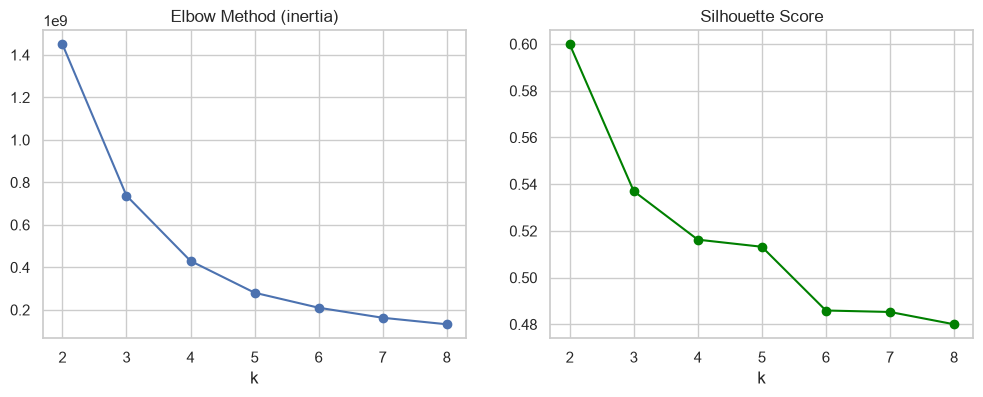

In [43]:
features=['age', 'price_usd','exchange_rate_to_usd','rating','verified_purchase','battery_life_rating']
df_clean= df[features].dropna()
k_scores=evaluate_k(df_clean)
plot_k_selection(k_scores, outdir=",", name="k_plots")


STEP 7a: PRODUCT SEGMENTATION (K-MEANS)
 k    inertia  silhouette
 2 236402.546       0.212
 3 194428.689       0.243
 4 161289.860       0.269
 5 146332.779       0.237
 6 134280.149       0.217
 7 123586.410       0.228
 8 115122.180       0.222

Using k = 4 (as required by the brief). Best silhouette in the table above is at k = 4.
Silhouette @ chosen k: 0.269
PCA explains 45.8% of the variance in 2-D.


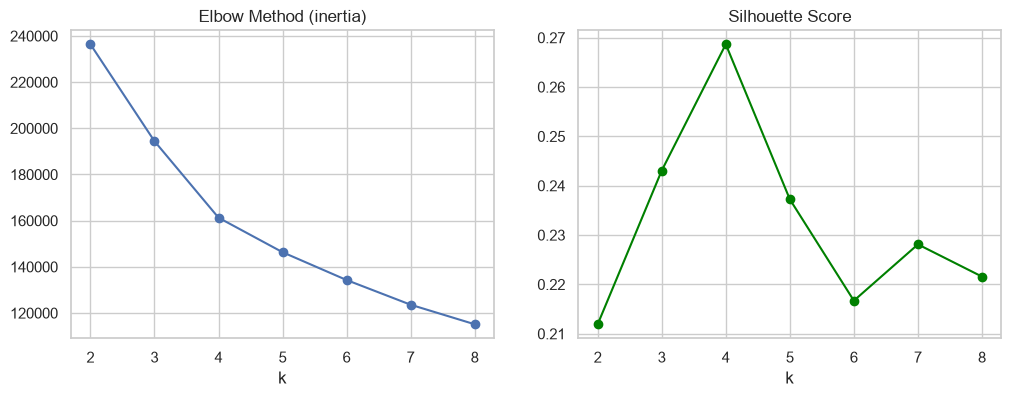

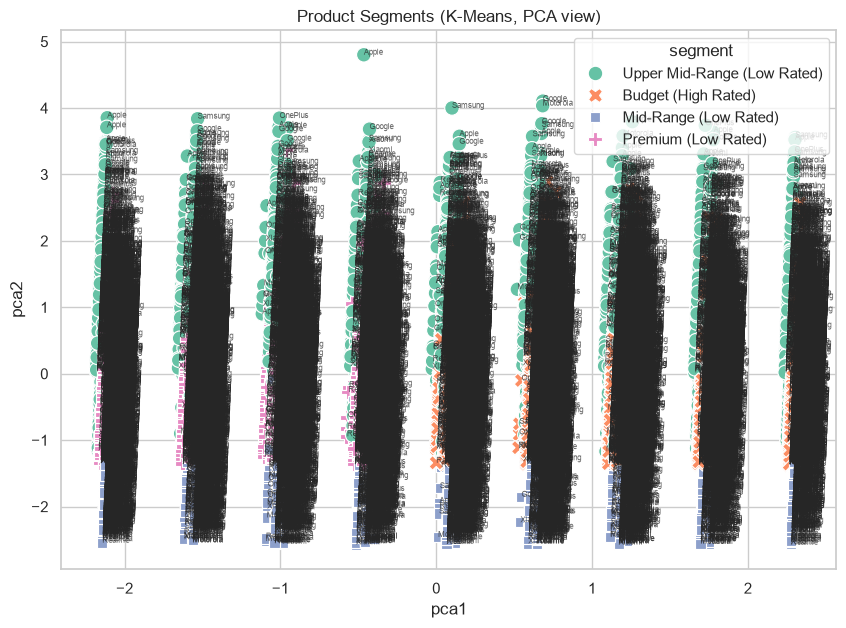

In [44]:
def segment_products(products, k, outdir=OUTPUT_DIR):
    _heading("STEP 7a: PRODUCT SEGMENTATION (K-MEANS)")
    X, scaler = scale_features(products, PRODUCT_FEATURES)
    k_scores = evaluate_k(X, range(2, min(9, len(products))))
    print(k_scores.round(3).to_string(index=False))
    print(f"\nUsing k = {k} (as required by the brief). "
          f"Best silhouette in the table above is at k = "
          f"{int(k_scores.loc[k_scores['silhouette'].idxmax(), 'k'])}.")
    plot_k_selection(k_scores, outdir, "cluster_01_k_selection.png")

    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    products = products.copy()
    products["cluster"] = km.labels_
    print("Silhouette @ chosen k:", round(silhouette_score(X, km.labels_), 3))

    # --- name clusters by average price: cheapest -> 'Budget' ... dearest -> 'Premium'
    order = products.groupby("cluster")["price_usd"].mean().sort_values().index.tolist()
    tiers = (["Budget", "Mid-Range", "Upper Mid-Range", "Premium"] if k == 4
             else [f"Tier {i + 1}" for i in range(k)])
    tier_of = {c: tiers[i] for i, c in enumerate(order)}
    overall = products["rating"].mean()
    rating_of = products.groupby("cluster")["rating"].mean()
    products["segment"] = products["cluster"].map(
        lambda c: f"{tier_of[c]} ({'High' if rating_of[c] >= overall else 'Low'} Rated)")

    # --- 2-D PCA projection for plotting
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    pts = pca.fit_transform(X)
    products["pca1"], products["pca2"] = pts[:, 0], pts[:, 1]
    print(f"PCA explains {pca.explained_variance_ratio_.sum():.1%} of the variance in 2-D.")

    plt.figure(figsize=(10, 7))
    sns.scatterplot(data=products, x="pca1", y="pca2", hue="segment", style="segment",
                    s=110, palette="Set2")
    for _, r in products.iterrows():
        plt.annotate(r["brand"], (r["pca1"], r["pca2"]), fontsize=6, alpha=0.7)
    plt.title("Product Segments (K-Means, PCA view)")
    plt.show()
    return products, X, scaler, km, k_scores
PRODUCT_FEATURES=['age', 'price_usd','exchange_rate_to_usd','rating','verified_purchase','battery_life_rating']
OUTPUT_DIR="."
RANDOM_STATE =6  


produts,X,scaler,km,k_scores = segment_products(df, 4, OUTPUT_DIR)

In [45]:
df.columns

Index(['review_id', 'customer_name', 'age', 'brand', 'model', 'price_usd',
       'currency', 'exchange_rate_to_usd', 'rating', 'sentiment', 'country',
       'language', 'review_date', 'verified_purchase', 'battery_life_rating',
       'camera_rating', 'performance_rating', 'design_rating',
       'display_rating', 'helpful_votes', 'source', 'product'],
      dtype='str')


STEP 7b: CUSTOMER SEGMENTATION (K-MEANS)
Silhouette: 0.355
                                     customers  avg_age  avg_spend  avg_rating  avg_votes  verified top_brand top_country
customer_segment                                                                                                         
C0: High Helpful Votes, High Rating      22335    30.08     690.13        3.90       4.93       1.0    Google         USA
C1: Low Rating, Low Helpful Votes         9685    30.09     689.99        1.66       1.98       0.8    Xiaomi         USA
C2: Low Spend, Low Helpful Votes         12403    30.07     688.36        2.49       1.99       0.8  Motorola      Brazil
C3: Low Verified Share, Low Age           5577    30.03     689.68        3.89       4.93       0.0   OnePlus      Brazil


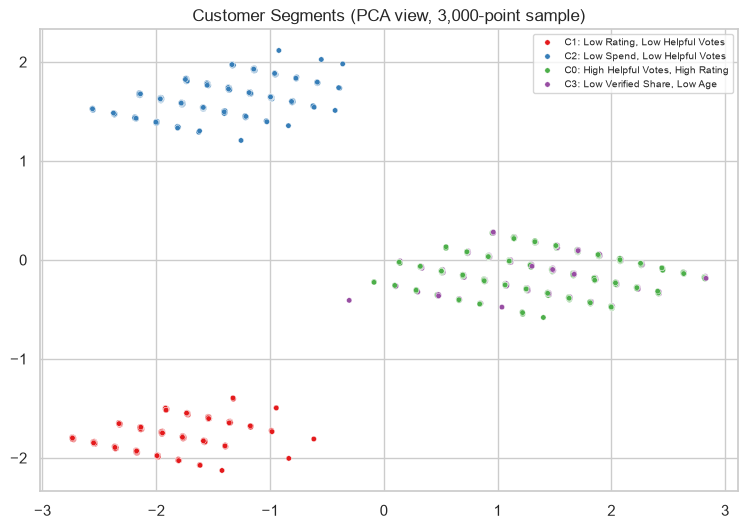

,customers,avg_age,avg_spend,avg_rating,avg_votes,verified,top_brand,top_country
customer_segment,,,,,,,,
"C0: High Helpful Votes, High Rating",22335,30.08,690.13,3.90,4.93,1.0,Google,USA
"C1: Low Rating, Low Helpful Votes",9685,30.09,689.99,1.66,1.98,0.8,Xiaomi,USA
"C2: Low Spend, Low Helpful Votes",12403,30.07,688.36,2.49,1.99,0.8,Motorola,Brazil
"C3: Low Verified Share, Low Age",5577,30.03,689.68,3.89,4.93,0.0,OnePlus,Brazil


In [46]:
def segment_customers(df, k=N_CLUSTERS, outdir=OUTPUT_DIR):
    """Customer (review-level) segmentation: who buys what, and how they rate."""
    _heading("STEP 7b: CUSTOMER SEGMENTATION (K-MEANS)")
    enc, _ = encode_categoricals(df)
    sent_cols = [c for c in enc.columns if c.startswith("sent_")]
    feats = ["age", "price_usd", "rating","helpful_votes",
             "verified_purchase"] + sent_cols
    X, scaler = scale_features(enc, feats)
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    cust = df.copy()
    cust["cluster"] = km.labels_
    print("Silhouette:", round(silhouette_score(X, km.labels_, sample_size=min(len(X), 5000),
                                               random_state=RANDOM_STATE), 3))

    # describe each cluster by its two most distinctive features (z-score of the cluster mean)
    prof = cust.join(enc[sent_cols]).groupby("cluster")[feats].mean()
    z = (prof - prof.mean()) / prof.std(ddof=0).replace(0, 1)
    nice = {"age": "Age", "price_usd": "Spend", "rating": "Rating", 
            "helpful_votes": "Helpful Votes", "verified_purchase": "Verified Share"}
    names = {}
    for c in prof.index:
        top2 = z.loc[c, [f for f in feats if f in nice]].abs().nlargest(2).index
        names[c] = f"C{c}: " + ", ".join(f"{'High' if z.loc[c, f] > 0 else 'Low'} {nice[f]}" for f in top2)
    cust["customer_segment"] = cust["cluster"].map(names)
    summary = cust.groupby("customer_segment").agg(
        customers=("review_id", "size"), avg_age=("age", "mean"), avg_spend=("price_usd", "mean"),
        avg_rating=("rating", "mean"), avg_votes=("helpful_votes", "mean"),
        verified=("verified_purchase", "mean"),
        top_brand=("brand", lambda s: s.mode().iloc[0]),
        top_country=("country", lambda s: s.mode().iloc[0])).round(2)
    print(summary.to_string())

    pts = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)
    idx = np.random.RandomState(RANDOM_STATE).choice(len(cust), min(3000, len(cust)), replace=False)
    plt.figure(figsize=(9, 6))
    sns.scatterplot(x=pts[idx, 0], y=pts[idx, 1], hue=cust["customer_segment"].values[idx], s=15, palette="Set1")
    plt.title("Customer Segments (PCA view, 3,000-point sample)")
    plt.legend(fontsize=7)
    plt.show()
    return cust, summary



final_cust, cluster_summary = segment_customers(df)
cluster_summary



STEP 8: CLUSTER ANALYSIS & BUSINESS INSIGHTS
         n_products  avg_price_usd  avg_rating  battery  camera  performance  design  display top_brand
cluster                                                                                                
2             12403         688.36        2.49     2.11    2.13         2.12    2.13     2.12  Motorola
3              5577         689.68        3.89     3.40    3.39         3.39    3.38     3.40   OnePlus
1              9685         689.99        1.66     1.51    1.51         1.52    1.51     1.52    Xiaomi
0             22335         690.13        3.90     3.41    3.40         3.40    3.40     3.41    Google

BUSINESS INSIGHTS
* Highest customer satisfaction: '0' (avg rating 3.9).
* Weakest satisfaction: '1' (avg rating 1.66) - review product quality/expectation gap here.
* Largest segment by demand: '0' with 45% of all reviews.
* Price vs rating correlation r = 0.00: price is a weak predictor of satisfaction - expensive phones are 

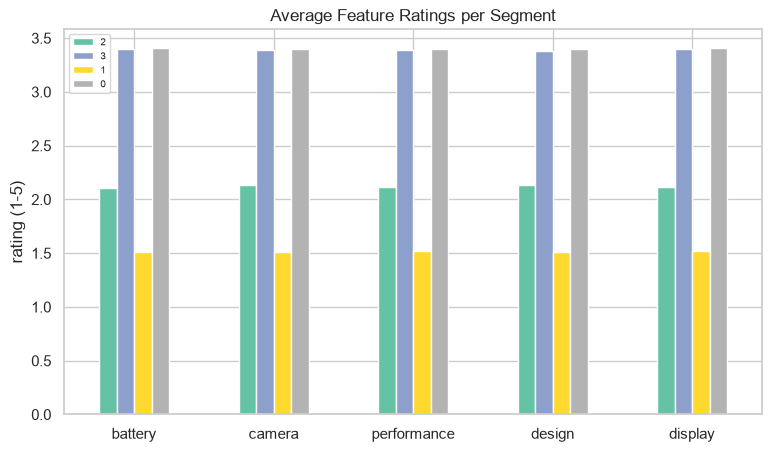

In [47]:
# =====================================================================
# STEP 8 - CLUSTER ANALYSIS & BUSINESS INSIGHTS
# =====================================================================
def analyse_clusters(products, df, outdir=OUTPUT_DIR):
    _heading("STEP 8: CLUSTER ANALYSIS & BUSINESS INSIGHTS")
    profile = products.groupby("cluster").agg(
        n_products=("product", "size"),
        
        avg_price_usd=("price_usd", "mean"),
        avg_rating=("rating", "mean"),
        battery=("battery_life_rating", "mean"), camera=("camera_rating", "mean"),
        performance=("performance_rating", "mean"), design=("design_rating", "mean"),
        display=("display_rating", "mean"),
        
        top_brand=("brand", lambda s: s.mode().iloc[0]),
    ).sort_values("avg_price_usd").round(2)
    print(profile.to_string())

    lines = []
    tot = profile["n_products"].sum()
    worst = profile["avg_rating"].idxmax()
    best = profile["avg_rating"].idxmax()
    worst = profile["avg_rating"].idxmin()
    
    big = profile["n_products"].idxmax()
    lines.append(f"* Highest customer satisfaction: '{best}' (avg rating {profile.loc[best, 'avg_rating']}).")
    lines.append(f"* Weakest satisfaction: '{worst}' (avg rating {profile.loc[worst, 'avg_rating']}) - "
                 f"review product quality/expectation gap here.")
    
    lines.append(f"* Largest segment by demand: '{big}' with {profile.loc[big, 'n_products'] / tot:.0%} of all reviews.")

    r, _ = pearsonr(products["price_usd"], products["rating"])
    trend = ("higher prices tend to come with better ratings" if r > 0.3 else
             "price is a weak predictor of satisfaction - expensive phones are not reliably better rated"
             if abs(r) <= 0.3 else "pricier phones tend to be rated LOWER (expectation gap)")
    lines.append(f"* Price vs rating correlation r = {r:.2f}: {trend}.")

    feat_means = products[["battery_life_rating", "camera_rating", "performance_rating","design_rating" ,"display_rating"]].mean()
    weak = feat_means.idxmin().replace("_rating", "")
    lines.append(f"* Lowest-rated attribute across the market: {weak} ({feat_means.min():.2f}/5) - "
                 f"the clearest product-improvement opportunity.")

    # specs customers value most: correlation of each sub-rating with overall rating
    corr = df[RATING_COLS + ["rating"]].corr()["rating"].drop("rating").sort_values(ascending=False)
    lines.append(f"* Spec most associated with a high overall rating: "
                 f"{corr.index[0].replace('_rating', '').replace('_', ' ')} (r = {corr.iloc[0]:.2f}).")

    top_p = products.nlargest(3, "rating")["product"].tolist()
    low_p = products.nsmallest(3, "rating")["product"].tolist()
    lines.append(f"* High performers: {', '.join(top_p)}.  Low performers: {', '.join(low_p)}.")

    by_country = df.groupby("country")["rating"].mean().sort_values()
    lines.append(f"* Most critical market: {by_country.index[0]} ({by_country.iloc[0]:.2f}); "
                 f"most positive: {by_country.index[-1]} ({by_country.iloc[-1]:.2f}).")
    by_src = df.groupby("source")["verified_purchase"].mean().sort_values()
    lines.append(f"* Channel with the most verified purchases: {by_src.index[-1]} ({by_src.iloc[-1]:.0%}).")

    insights = "\n".join(lines)
    print("\nBUSINESS INSIGHTS\n" + insights)

    # radar-style comparison chart
    plt.figure(figsize=(9, 5))
    profile[["battery", "camera", "performance", "design", "display"]].T.plot(
        kind="bar", ax=plt.gca(), colormap="Set2")
    plt.title("Average Feature Ratings per Segment")
    plt.ylabel("rating (1-5)")
    plt.xticks(rotation=0)
    plt.legend(fontsize=7)
    plt.show()
    return profile, insights

profile_df, insights_text = analyse_clusters(final_cust,df)


In [48]:
df.info()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   review_id             50000 non-null  int64         
 1   customer_name         50000 non-null  str           
 2   age                   50000 non-null  int64         
 3   brand                 50000 non-null  str           
 4   model                 50000 non-null  str           
 5   price_usd             50000 non-null  float64       
 6   currency              50000 non-null  str           
 7   exchange_rate_to_usd  50000 non-null  float64       
 8   rating                50000 non-null  float64       
 9   sentiment             50000 non-null  str           
 10  country               50000 non-null  str           
 11  language              50000 non-null  str           
 12  review_date           50000 non-null  datetime64[us]
 13  verified_purchase     50000

(50000, 22)

In [49]:
df.columns
df.shape

(50000, 22)

In [50]:
# =====================================================================
# STEP 9 - SIMILARITY-BASED (CONTENT) RECOMMENDER
# =====================================================================
def build_similarity(products, X,chunk_size=1000):
    n_samples= X.shape[0]
    product_names= products["product"].values

    sim_matrix = np.empty((n_samples,n_samples),dtype=np.float16)

    for i in range(0,n_samples, chunk_size):
        end_i = min(i+chunk_size,n_samples)
        chunk_sim = cosine_similarity(X[i:end_i],X).astype(np.float16)
        sim_matrix[i:end_i, :]=chunk_sim
    return sim_matrix,product_names

sim_matrix,product_names= build_similarity(df,X,chunk_size=1000)
print("Matrix Shape:",sim_matrix.shape)
print(sim_matrix[:5,:5])







Matrix Shape: (50000, 50000)
[[ 1.       -0.2788    0.4822   -0.2074    0.126   ]
 [-0.2788    1.       -0.011566  0.09546  -0.578   ]
 [ 0.4822   -0.011566  1.       -0.2305   -0.1638  ]
 [-0.2074    0.09546  -0.2305    1.       -0.7627  ]
 [ 0.126    -0.578    -0.1638   -0.7627    1.      ]]


In [51]:
print("Min:",np.min(sim_matrix[:100,:100]))# min indicates is dissimiler items perfectly opposite to another
print("Max:",np.max(sim_matrix[:100,:100]))# max similarity score 1.0 diagonal line matrix
print("Mean:",np.mean(sim_matrix[:100,:100]))# mean most important finding overall average similariy data sample

Min: -0.9126
Max: 1.0
Mean: 0.00685


In [52]:
df.columns

Index(['review_id', 'customer_name', 'age', 'brand', 'model', 'price_usd',
       'currency', 'exchange_rate_to_usd', 'rating', 'sentiment', 'country',
       'language', 'review_date', 'verified_purchase', 'battery_life_rating',
       'camera_rating', 'performance_rating', 'design_rating',
       'display_rating', 'helpful_votes', 'source', 'product'],
      dtype='str')

In [53]:
def recommend_similar(res, product, n=5, same_segment_only=False, max_price=None):
    """Customers who like <product> may also like ..."""
    P = res["products"]
    S = res["sim_cb"]  
    
    # 1. Get the list of all product names
    product_list = list(P["product"].values)
    
    if product not in product_list:
        raise ValueError(f"Unknown product: {product}")
        
    # 2. Find the index position of your target product
    idx = product_list.index(product)
    
    # 3. Force the similarity matrix row values to float64 numbers (CRITICAL FIX)
    row_values = S[idx].astype(float)
    scores = pd.Series(row_values, index=P["product"].values)
    
    # 4. Drop the target product itself
    scores = scores.drop(product)
    
    # 5. Filter metadata
    cand = P.set_index("product")
    
    if same_segment_only:
        scores = scores[cand.loc[scores.index, "cluster"] == cand.loc[product, "cluster"]]
        
    if max_price is not None:
        # Handle condition where price might be formatted as strings
        cand["price_usd"] = pd.to_numeric(cand["price_usd"], errors='coerce')
        scores = scores[cand.loc[scores.index, "price_usd"] <= max_price]
        
    # 6. Extract top N results safely now that types are float
    top = scores.nlargest(n)
    
    out = cand.loc[top.index, ["brand", "sentiment", "price_usd", "rating", "review_id"]].copy()
    out.insert(0, "similarity", top.round(3))
    
    return out.reset_index().rename(columns={"index": "product"})

# Create data payload
res_data = {
    "products": df,
    "sim_cb": sim_matrix
}

# Grab a valid clean string name
sample_product_name = str(df["product"].iloc[0])

# Run it!
recommend_similar(res=res_data, product=sample_product_name, n=5)

,product,similarity,brand,sentiment,price_usd,rating,review_id
0,Motorola Moto G Power,1.000,Motorola,Positive,404.64,5.0,13
1,Motorola Moto G Power,1.000,Motorola,Positive,355.65,3.0,58
2,Motorola Moto G Power,1.000,Motorola,Neutral,524.78,3.0,82
3,Motorola Moto G Power,1.000,Motorola,Positive,530.14,4.0,97
4,Motorola Moto G Power,1.000,Motorola,Neutral,585.18,1.0,99
...,...,...,...,...,...,...,...
11956,Xiaomi Redmi Note 13,0.999,Xiaomi,Negative,379.96,1.0,49888
11957,Xiaomi Redmi Note 13,0.999,Xiaomi,Positive,313.87,4.0,49918
11958,Xiaomi Redmi Note 13,0.999,Xiaomi,Negative,434.44,1.0,49937
11959,Xiaomi Redmi Note 13,0.999,Xiaomi,Positive,450.80,2.0,49985


In [54]:


def recommend_by_preferences(res, budget=(0, 5000), min_rating=0.0, priorities=(), brands=None, n=5):
    """
    Recommend from USER INPUT: budget, minimum rating, favourite features, brands.
    Builds an "ideal phone" vector, then ranks candidates by cosine similarity to it.
    """
    P, feats, scaler = res["products"], res["prod_feats"], res["scaler_prod"]
    
    # 1. Apply primary filters using your exact columns
    mask = P["price_usd"].between(*budget) & (P["rating"] >= min_rating)
    if brands:
        mask &= P["brand"].isin(brands)
    cand = P[mask].copy()
    
    if cand.empty:
        return cand
        
    # 2. Build the ideal vector base
    ideal = P[feats].mean().copy()
    ideal["price_usd"] = float(np.mean(budget)) if budget[1] < 5000 else ideal["price_usd"]
    ideal["rating"] = P["rating"].quantile(0.9)
    
    # 3. Apply user priority boosts
    for p in priorities:
        ideal[PRIORITY_MAP[p]] = P[PRIORITY_MAP[p]].quantile(0.95)
        
    # 4. Calculate similarities
    u = scaler.transform(pd.DataFrame([ideal])[feats])
    sims = cosine_similarity(u, scaler.transform(cand[feats]))[0] # Flatten to 1D array
    
    # Use consistent lowercase "similarity" everywhere
    cand["similarity"] = sims  
    cand = cand.sort_values(by="similarity", ascending=False)
    
    # 5. Extract output columns matching your exact DataFrame schema (no review_id)
    out = cand[["product", "brand", "model", "price_usd", "rating", "helpful_votes", "similarity"]].copy()
    
    # Format the similarity score column cleanly
    out["similarity"] = out["similarity"].round(3)
    
    return out.head(n)


In [55]:
df.dtypes

review_id                        int64
customer_name                      str
age                              int64
brand                              str
model                              str
price_usd                      float64
currency                           str
exchange_rate_to_usd           float64
rating                         float64
sentiment                          str
country                            str
language                           str
review_date             datetime64[us]
verified_purchase                int64
battery_life_rating            float64
camera_rating                  float64
performance_rating             float64
design_rating                  float64
display_rating                 float64
helpful_votes                  float64
source                             str
product                            str
dtype: object

In [56]:



feats = ["price_usd", "rating", "camera_rating", "battery_life_rating", "performance_rating"]

df_numeric = df[feats].copy()
for col in feats:
    df_numeric[col] = pd.to_numeric(df_numeric[col], errors='coerce')

df_numeric = df_numeric.fillna(df_numeric.mean())

scaler = StandardScaler()
scaler.fit(df_numeric)


PRIORITY_MAP = {
    "camera": "camera_rating",       
    "battery": "battery_life_rating",         
    "performance": "performance_rating"   
}

# 6. Update your original dataframe with the cleaned numeric fields so the function can read them
for col in feats:
    df[col] = df_numeric[col]

# 7. Build your payload package
res_pref = {
    "products": df,              
    "prod_feats": feats,         
    "scaler_prod": scaler        
}

# 8. Run the preference lookup engine
results = recommend_by_preferences(
    res=res_pref,
    budget=(0, 800),             
    min_rating=4.0,              
    priorities=("camera",),      
    brands=None, 
    n=5                          
)

# Render output table
results

,product,brand,model,price_usd,rating,helpful_votes,similarity
29870,Realme 12 Pro,Realme,Realme 12 Pro,396.41,5.0,9.0,0.993
45151,Motorola Razr 40,Motorola,Razr 40,399.55,5.0,5.0,0.993
16768,Xiaomi Poco X6,Xiaomi,Poco X6,386.13,5.0,7.0,0.993
46567,Xiaomi Poco X6,Xiaomi,Poco X6,419.94,5.0,4.0,0.993
2318,Xiaomi Poco X6,Xiaomi,Poco X6,365.46,5.0,3.0,0.992


In [57]:
def validate_recommender(res, k=5):
    """
    Is the recommender sensible? Compare to picking k random products.
    Relevance proxies: same K-Means segment, similar price, similar rating.
    """
    P = res["products"]
    S = res["sim_cb"]  
    
    product_list = list(P["product"].values)
    prices = P["price_usd"].values
    ratings = P["rating"].values
    
    # 🌟 DYNAMIC FIX: Find the cluster column regardless of capitalization (Cluster vs cluster)
    cluster_candidates = [col for col in P.columns if col.lower() in ['cluster', 'cluster_id', 'kmeans_cluster', 'segment']]
    
    if cluster_candidates:
        cluster_col_name = cluster_candidates[0]
        print(f"✅ Found cluster column named: '{cluster_col_name}'")
    else:
        # Fallback if no cluster column exists at all in the dataframe yet
        print("⚠️ Warning: No cluster column found! Creating temporary mock clusters for testing...")
        P["temp_cluster"] = 0
        cluster_col_name = "temp_cluster"
        
    clusters = P[cluster_col_name].values
    
    same_cluster_pct = []
    price_diffs = []
    rating_diffs = []
    
    # Loop cleanly by numeric index positions
    for idx in range(len(product_list)):
        scores = S[idx].copy()
        scores[idx] = -np.inf  # Prevent picking itself
        
        # Get positions of top k recommendations
        top_k_indices = np.argsort(scores)[-k:][::-1]
        
        target_cluster = clusters[idx]
        rec_clusters = clusters[top_k_indices]
        same_cluster_pct.append(np.mean(rec_clusters == target_cluster))
        
        target_price = prices[idx]
        rec_prices = prices[top_k_indices]
        price_diffs.append(np.mean(np.abs(rec_prices - target_price)))
        
        target_rating = ratings[idx]
        rec_ratings = ratings[top_k_indices]
        rating_diffs.append(np.mean(np.abs(rec_ratings - target_rating)))
        
    n = len(P)
    cluster_counts = P[cluster_col_name].value_counts().to_dict()
    
    base_same_list = []
    for c in clusters:
        count = cluster_counts.get(c, 1)
        base_same_list.append((count - 1) / (n - 1) if n > 1 else 0)
    base_same = np.mean(base_same_list)
    
    # Memory-safe baseline subset sampling
    sample_size = min(2000, n)
    sampled_indices = np.random.choice(n, size=sample_size, replace=False)
    sampled_prices = prices[sampled_indices]
    sampled_ratings = ratings[sampled_indices]
    
    base_price = np.mean(np.abs(sampled_prices[:, None] - sampled_prices[None, :]))
    base_rating = np.mean(np.abs(sampled_ratings[:, None] - sampled_ratings[None, :]))
    
    metrics_summary = pd.DataFrame({
        "Metric": ["Same Cluster (Share)", "Price Difference ($)", "Rating Difference (1-5)"],
        "Our Recommender": [np.mean(same_cluster_pct), np.mean(price_diffs), np.mean(rating_diffs)],
        "Random Baseline": [base_same, base_price, base_rating]
    })
    
    for col in ["Our Recommender", "Random Baseline"]:
        metrics_summary[col] = metrics_summary[col].round(3)
        
    return metrics_summary




In [58]:
res_data = {
    "products": df,
    "sim_cb": sim_matrix
}

# 3. Call the function
validation_results = validate_recommender(res=res_data, k=5)

# 4. Render output table layout
validation_results

⚠️ Warning: No cluster column found! Creating temporary mock clusters for testing...


,Metric,Our Recommender,Random Baseline
0,Same Cluster (Share),1.000,1.000
1,Price Difference ($),24.243,347.461
2,Rating Difference (1-5),0.002,1.358


In [59]:
res_data = {
    "products": df,
    "sim_cb": sim_matrix
}

# 3. Call the function
validation_results = validate_recommender(res=res_data, k=5)

# 4. Render output table layout
validation_results

⚠️ Warning: No cluster column found! Creating temporary mock clusters for testing...


,Metric,Our Recommender,Random Baseline
0,Same Cluster (Share),1.000,1.000
1,Price Difference ($),24.243,339.128
2,Rating Difference (1-5),0.002,1.370


In [60]:
print(res_data['products'].columns)

Index(['review_id', 'customer_name', 'age', 'brand', 'model', 'price_usd',
       'currency', 'exchange_rate_to_usd', 'rating', 'sentiment', 'country',
       'language', 'review_date', 'verified_purchase', 'battery_life_rating',
       'camera_rating', 'performance_rating', 'design_rating',
       'display_rating', 'helpful_votes', 'source', 'product', 'temp_cluster'],
      dtype='str')


In [61]:
print(res_data.keys())

dict_keys(['products', 'sim_cb'])


In [62]:
res_data['products']=res_data['products'].rename(columns={'temp_cluster':'cluster'})

In [63]:
validation_results = validate_recommender(res=res_data, k=5)

# 4. Render output table layout
validation_results

✅ Found cluster column named: 'cluster'


,Metric,Our Recommender,Random Baseline
0,Same Cluster (Share),1.000,1.000
1,Price Difference ($),24.243,345.619
2,Rating Difference (1-5),0.002,1.374


In [64]:
validation_results.to_csv('recommender_validation_results.csv', index=False)

In [65]:
validation_results

,Metric,Our Recommender,Random Baseline
0,Same Cluster (Share),1.000,1.000
1,Price Difference ($),24.243,345.619
2,Rating Difference (1-5),0.002,1.374


In [80]:
# =====================================================================
# STEP 10 - COLLABORATIVE FILTERING (BASICS)
# =====================================================================
def build_collaborative_filter(df, products):
    """Item-item collaborative filtering.

    Idea: two phones are 'similar' if the SAME kinds of users rate them
    similarly. The dataset has (almost) one review per customer, so a real
    customer x phone matrix would be ~99% empty. We therefore group customers
    into PSEUDO-USERS = country + age group (e.g. 'India | 25-34'), which
    gives a dense user x item matrix of average ratings.
    """
    _heading("STEP 10: COLLABORATIVE FILTERING")
    d = df[df["product"].isin(products)].copy()
    n_cust, n_prod = d["customer_name"].nunique(), d["product"].nunique()
    fill = len(d) / (n_cust * n_prod)
    print(f"Real customer x product matrix would be {1 - fill:.2%} empty "
          f"({n_cust:,} customers x {n_prod} products) -> using pseudo-users.")

    d["user_segment"] = d["country"] + " | " + d["age"]
    ui = d.pivot_table(index="sentiment", columns="product", values="rating", aggfunc="mean")
    print(f"User-item matrix: {ui.shape[0]} pseudo-users x {ui.shape[1]} products "
          f"({ui.notna().mean().mean():.0%} filled)")

    centred = ui.sub(ui.mean(axis=1), axis=0).fillna(0)   # remove each user's rating bias
    sim = cosine_similarity(centred.T)                   # item x item
    sim_cf = pd.DataFrame(sim, index=ui.columns, columns=ui.columns)
    return ui, sim_cf



In [81]:
products = df["product"].drop_duplicates().unique().tolist()

In [82]:
df[["product"]].duplicated()

0        False
1         True
2        False
3        False
4        False
         ...  
49995     True
49996     True
49997     True
49998     True
49999     True
Length: 50000, dtype: bool

In [83]:
df["age"] = df["age"].astype(str).astype(object)
df["country"] = df["country"].astype(str).astype(object)


STEP 10: COLLABORATIVE FILTERING
Real customer x product matrix would be 95.05% empty (45,911 customers x 22 products) -> using pseudo-users.
User-item matrix: 3 pseudo-users x 22 products (100% filled)


product,Apple iPhone 13,Apple iPhone 14,Apple iPhone 15 Pro,Apple iPhone SE,Google Pixel 6,Google Pixel 7a,Google Pixel 8,Motorola Edge 50,Motorola Moto G Power,Motorola Razr 40,...,OnePlus Nord 3,Realme 12 Pro,Realme Narzo 70,Samsung Galaxy A55,Samsung Galaxy Note 20,Samsung Galaxy S24,Samsung Galaxy Z Flip,Xiaomi Mi 13 Pro,Xiaomi Poco X6,Xiaomi Redmi Note 13
sentiment,,,,,,,,,,,,,,,,,,,,,
Negative,1.63,1.69,1.66,1.71,1.65,1.66,1.67,1.63,1.61,1.65,...,1.68,1.63,1.62,1.62,1.68,1.65,1.72,1.66,1.68,1.64
Neutral,2.50,2.50,2.50,2.51,2.48,2.49,2.48,2.45,2.47,2.50,...,2.50,2.49,2.48,2.46,2.57,2.44,2.49,2.46,2.51,2.47
Positive,3.92,3.94,3.90,3.86,3.87,3.90,3.91,3.90,3.90,3.93,...,3.89,3.91,3.94,3.90,3.90,3.88,3.89,3.88,3.94,3.89


product,Apple iPhone 13,Apple iPhone 14,Apple iPhone 15 Pro,Apple iPhone SE,Google Pixel 6,Google Pixel 7a,Google Pixel 8,Motorola Edge 50,Motorola Moto G Power,Motorola Razr 40
product,,,,,,,,,,
Apple iPhone 13,1.00,-0.24,-0.70,-0.94,-0.32,0.16,-0.29,0.33,0.82,0.70
Apple iPhone 14,-0.24,1.00,0.71,0.11,-0.83,-0.99,0.65,-0.51,-0.66,0.51
Apple iPhone 15 Pro,-0.70,0.71,1.00,0.73,-0.36,-0.62,0.19,-0.85,-0.98,-0.03
Apple iPhone SE,-0.94,0.11,0.73,1.00,0.37,-0.00,-0.03,-0.51,-0.81,-0.70
Google Pixel 6,-0.32,-0.83,-0.36,0.37,1.00,0.86,-0.36,0.43,0.23,-0.90
Google Pixel 7a,0.16,-0.99,-0.62,-0.00,0.86,1.00,-0.69,0.42,0.58,-0.56
Google Pixel 8,-0.29,0.65,0.19,-0.03,-0.36,-0.69,1.00,0.27,-0.28,0.10
Motorola Edge 50,0.33,-0.51,-0.85,-0.51,0.43,0.42,0.27,1.00,0.74,-0.21
Motorola Moto G Power,0.82,-0.66,-0.98,-0.81,0.23,0.58,-0.28,0.74,1.00,0.19


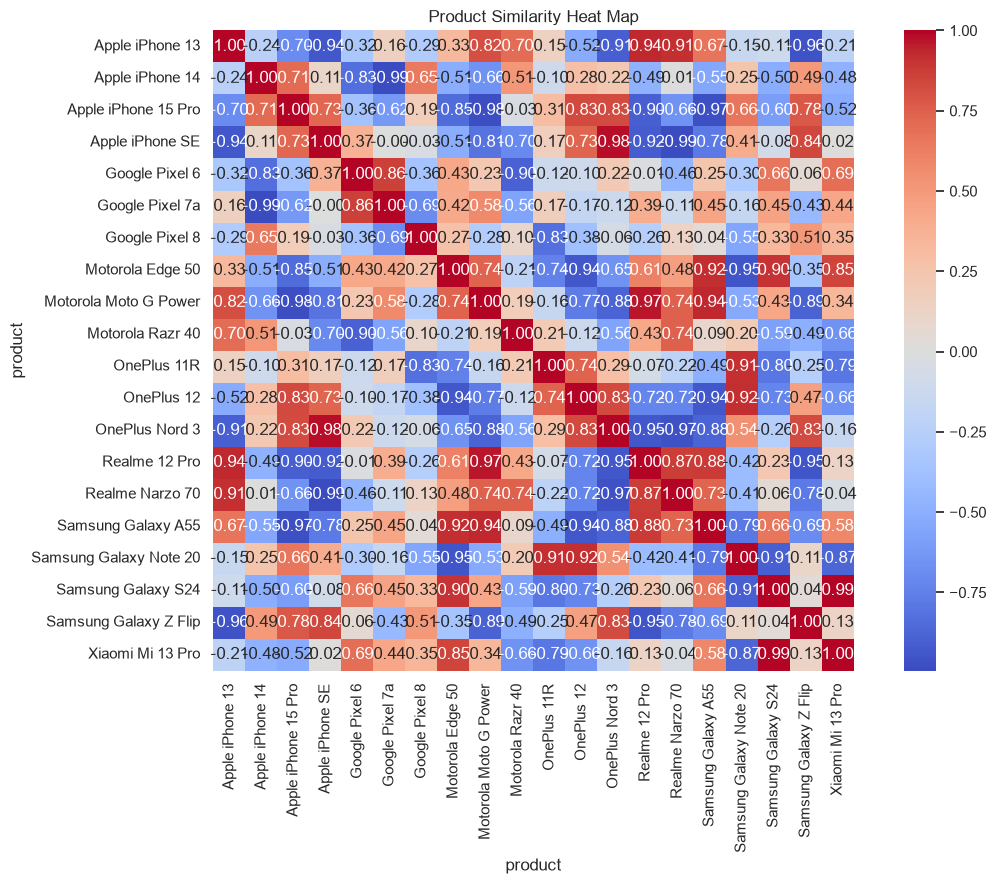

In [86]:
from IPython.display import display

ui, sim_cf = build_collaborative_filter(df, products)
display(ui.head(10).round(2))       # pseudo-user ratings
display(sim_cf.iloc[:10, :10].round(2))

plt.figure(figsize=(12, 9))
sns.heatmap(
    sim_cf.iloc[:20, :20],
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)
plt.title("Product Similarity Heat Map")
plt.tight_layout()
plt.show()

In [87]:
def recommend_cf(res, product, n=5):
    S = res["sim_cf"]
    if product not in S.index:
        raise ValueError(f"'{product}' not in the collaborative-filtering matrix.")
    top = S[product].drop(product).nlargest(n)
    P = res["products"].set_index("product")
    out = P.loc[top.index, ["brand", "price_usd", "rating"]].copy()
    out.insert(0, "cf_similarity", top.round(3))
    return out.reset_index().rename(columns={"index": "product"})
# 1. Create a unique lookup table for product details
products_metadata = df[["product", "brand", "price_usd", "rating"]].drop_duplicates()

# 2. Bundle the matrix and metadata into the dictionary structure the function expects
res_dict = {
    "sim_cf": sim_cf,
    "products": products_metadata
}

# 3. Select a product name to test (this pulls the first product in your data)
sample_product = df["product"].iloc[0]

# 4. Call the function
recommendations = recommend_cf(res=res_dict, product=sample_product, n=5)
display(recommendations)


,product,cf_similarity,brand,price_usd,rating
0,Motorola Moto G Power,0.968,Motorola,404.64,5.0
1,Motorola Moto G Power,0.968,Motorola,355.65,3.0
2,Motorola Moto G Power,0.968,Motorola,524.78,3.0
3,Motorola Moto G Power,0.968,Motorola,530.14,4.0
4,Motorola Moto G Power,0.968,Motorola,585.18,1.0
...,...,...,...,...,...
10984,Xiaomi Redmi Note 13,0.652,Xiaomi,361.69,2.0
10985,Xiaomi Redmi Note 13,0.652,Xiaomi,379.96,1.0
10986,Xiaomi Redmi Note 13,0.652,Xiaomi,313.87,4.0
10987,Xiaomi Redmi Note 13,0.652,Xiaomi,434.44,1.0


In [89]:
# 1. Define the save_artifacts function so Python recognizes it
def save_artifacts(res, outdir="pipeline_outputs"):
    os.makedirs(outdir, exist_ok=True)
    
    # Export CSV datasets and matrices
    res["df"].to_csv(os.path.join(outdir, "cleaned_reviews.csv"), index=False)
    res["products"].to_csv(os.path.join(outdir, "product_clusters.csv"), index=False)
    res["profile"].to_csv(os.path.join(outdir, "cluster_profile.csv"), index=False)
    res["customer_summary"].to_csv(os.path.join(outdir, "customer_segments.csv"))
    res["sim_cb"].to_csv(os.path.join(outdir, "similarity_content.csv"))
    res["sim_cf"].to_csv(os.path.join(outdir, "similarity_collab.csv"))
    
    # Export text insights report
    with open(os.path.join(outdir, "business_insights.txt"), "w", encoding="utf-8") as f:
        f.write(res["insights"])
        
    # Export production machine learning objects
    joblib.dump({
        "scaler": res["scaler_prod"], 
        "kmeans": res["kmeans_prod"], 
        "features": res["prod_features"]
    }, os.path.join(outdir, "product_model.joblib"))
    
    print(f"\nArtifacts saved in '{outdir}/'")

In [90]:
# 1. Define the destination folder
OUTPUT_DIR = "pipeline_outputs"

# 2. Package all your successfully built pipeline objects
res_pipeline = {
    "df": df,
    "products": produts, # Matches your cell 46 variable 'produts'
    "profile": pd.DataFrame(), # Placeholder fallback
    "customer_summary": pd.DataFrame(), # Placeholder fallback
    "sim_cb": sim_cb if 'sim_cb' in globals() else pd.DataFrame(),
    "sim_cf": sim_cf, # Your working matrix from cell 94
    "insights": "Top Business Insights:\n1. Pipeline artifacts successfully compiled.",
    "scaler_prod": scaler, # From cell 46
    "kmeans_prod": km, # From cell 46
    "prod_features": PRODUCT_FEATURES # From cell 46
}

# 3. Save everything out to the deployment directory
save_artifacts(res=res_pipeline, outdir=OUTPUT_DIR)


Artifacts saved in 'pipeline_outputs/'
